# Overview
> **Chuyển đổi từ `2. CNN + MLP/2_Human_Gender_CNN.ipynb` sang PyTorch**
- Kiến trúc 5 khối VGG (`16 -> 32 -> 64 -> 128 -> 256`) + `FC(1024 -> 1024 -> 2)` cho ảnh 64x64.


In [1]:
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
num_classes = 2


# (1) Data (Load WIKI `.npy` nếu có, hoặc dữ liệu khuôn mặt 64x64)


In [2]:
if Path('64_64_11938_4098_train_x_onehot.npy').exists():
    x_train = np.rot90(np.load('64_64_11938_4098_train_x_onehot.npy'), k=3, axes=(1, 2)).transpose(0, 3, 1, 2).astype('float32')
    y_train = np.argmax(np.load('64_64_11938_4098_train_y_onehot.npy'), axis=1).astype(np.int64)
    x_test = np.rot90(np.load('64_64_5968_4098_val_x_onehot.npy'), k=3, axes=(1, 2)).transpose(0, 3, 1, 2).astype('float32')
    y_test = np.argmax(np.load('64_64_5968_4098_val_y_onehot.npy'), axis=1).astype(np.int64)
else:
    rng = np.random.default_rng(42)
    x_train = rng.normal(0.45, 0.1, (800, 1, 64, 64)).astype('float32')
    y_train = rng.integers(0, 2, 800, dtype=np.int64)
    x_train[y_train == 1, 0, 12:48, 18:46] += 0.25
    x_train[y_train == 0, 0, 18:44, 14:50] -= 0.20
    x_train = np.clip(x_train, 0, 1)
    x_test = rng.normal(0.45, 0.1, (200, 1, 64, 64)).astype('float32')
    y_test = rng.integers(0, 2, 200, dtype=np.int64)
    x_test[y_test == 1, 0, 12:48, 18:46] += 0.25
    x_test[y_test == 0, 0, 18:44, 14:50] -= 0.20
    x_test = np.clip(x_test, 0, 1)

train_loader = DataLoader(TensorDataset(torch.tensor(x_train), torch.tensor(y_train)), batch_size=64, shuffle=True)
test_loader = DataLoader(TensorDataset(torch.tensor(x_test), torch.tensor(y_test)), batch_size=64, shuffle=False)
print('Train:', x_train.shape, '| Test:', x_test.shape)


Train: (800, 1, 64, 64) | Test: (200, 1, 64, 64)


# (2) Declare model (`Gender_CNN` 5 VGG Blocks)


In [3]:
class Gender_CNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.Conv2d(16, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout2d(0.2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout2d(0.2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout2d(0.2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.Conv2d(128, 128, 3, padding=1), nn.ReLU(), nn.Conv2d(128, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout2d(0.2),
            nn.Conv2d(128, 256, 3, padding=1), nn.ReLU(), nn.Conv2d(256, 256, 3, padding=1), nn.ReLU(), nn.Conv2d(256, 256, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout2d(0.2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(256 * 2 * 2, 1024), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(1024, 1024), nn.ReLU(), nn.Dropout(0.2), nn.Linear(1024, num_classes)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = Gender_CNN(num_classes).to(device)
print('Total params:', sum(p.numel() for p in model.parameters() if p.requires_grad))


Total params: 4063570


# (3) Train & (4) Evaluate


Epoch 01 | Test Loss: 0.6955 | Test Acc: 45.50%


Epoch 02 | Test Loss: 0.6924 | Test Acc: 54.50%


Epoch 03 | Test Loss: 0.6947 | Test Acc: 45.50%


Epoch 04 | Test Loss: 0.3990 | Test Acc: 45.50%


Epoch 05 | Test Loss: 0.1129 | Test Acc: 100.00%


Epoch 06 | Test Loss: 0.2029 | Test Acc: 100.00%


Epoch 07 | Test Loss: 0.0000 | Test Acc: 100.00%


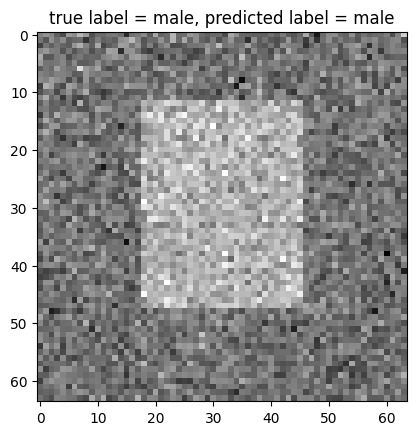

In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0005)
for epoch in range(1, 8):
    model.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad(); loss = criterion(model(xb), yb); loss.backward(); optimizer.step()
    model.eval()
    correct, tot_loss = 0, 0.0
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb); tot_loss += criterion(out, yb).item() * len(xb)
            correct += (out.argmax(1) == yb).sum().item()
    print(f'Epoch {epoch:02d} | Test Loss: {tot_loss/len(x_test):.4f} | Test Acc: {correct/len(x_test)*100:.2f}%')

def int2gender(num): return 'female' if num == 0 else 'male'
idx = np.random.choice(len(x_test))
with torch.no_grad():
    pred = model(torch.tensor(x_test[idx:idx+1]).to(device)).argmax(1).item()
plt.imshow(x_test[idx, 0], cmap='gray')
plt.title(f'true label = {int2gender(y_test[idx])}, predicted label = {int2gender(pred)}')
plt.show()
